### 1. Generate the $n(z)$ ensemble 

In [56]:
# Necessary imports #

# General #

import numpy as np
from scipy import integrate
import matplotlib.pyplot as plt
from scipy import integrate
from sklearn.gaussian_process.kernels import (
    RBF, Matern, ConstantKernel as C
)
import sys
import os

import euclidlib as el
import seaborn as sns

repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(repo_root)

# GPs #
import importlib
import binz.gp
import binz.ensemble

importlib.reload(binz.gp)
importlib.reload(binz.ensemble)

from binz.gp import (
    normalize_dndz, resample_dndz, compute_cdf_nodes,
    reconstruct_per_bin, reconstruct_all_bins, resample_dndz_gp
)

from binz.ensemble import (
    generate_bin1_ensemble, fit_params_ens, recon_ens_from_params
)

# Normalising flow #

from binz.norm_flow import norm_flow_per_bin, get_flow_log_prob, build_flow


# Plotting #

import matplotlib as mpl 
mpl.rcParams['font.family'] = "serif"
mpl.rcParams['font.serif'] = "Times New Roman"
mpl.rcParams['text.usetex'] = True

### Constructing the ensemble 

In [41]:
# Load in the DR1 n(z) 
zs = np.linspace(1e-4, 3, 100)
z_nz, nz_heracles = el.phz.redshift_distributions('/home/jipdebuck/nz_example.fits')

# Normalize both dndz_pos and dndz_she
dndz_pos_norm = normalize_dndz(nz_heracles, z_nz)
dndz_she_norm = normalize_dndz(nz_heracles, z_nz)

# Resampling the normalized dndz with 100 values
my_dndz_pos_norm = resample_dndz(dndz_pos_norm, z_nz, zs)
my_dndz_she_norm = resample_dndz(dndz_she_norm, z_nz, zs)

In [43]:
# Creating a list of plausible n(z) realizations using generate_bin1_ensemble

z_ens_list, nz_ensemble_list = zip(*[generate_bin1_ensemble(N_ens=200, nz=dndz_she_norm[i], N_z=3001, mean_shift_sigma=0.02,
        width_shift_sigma=0.02, shape_noise_sigma=0.05) for i in range(1, 7)])

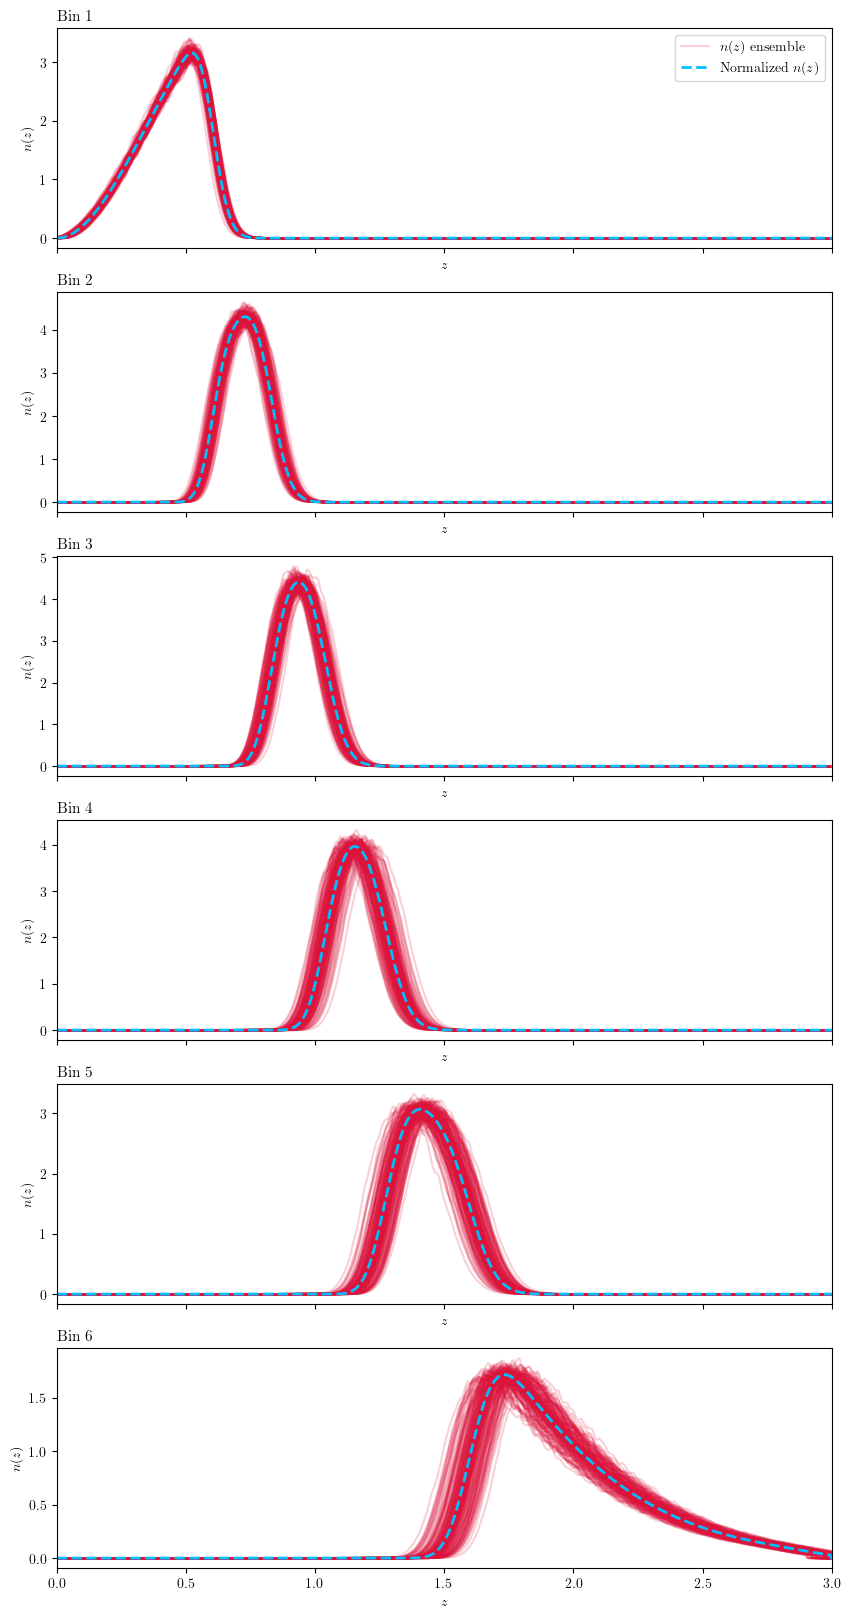

In [44]:
# Plotting the ensemble 

z_grid = z_ens_list[0]

fig, axes = plt.subplots(6, 1, figsize=(10,20), sharex=True)
axes = axes.flatten()
for i in range(len(nz_ensemble_list)):
    nz_ens = nz_ensemble_list[i]
    for j, nz in enumerate(nz_ens):
        if i == 0 and j == 0:
            axes[i].plot(z_grid, nz, color='crimson', alpha=0.2, label='$n(z)$ ensemble')
        else:
            axes[i].plot(z_grid, nz, color='crimson', alpha=0.2)
        
    axes[i].set_xlim(0, 3)
    axes[i].set_title(f"Bin {i+1}", loc="left", fontsize=11)
    axes[i].set_xlabel("$z$")
    axes[i].set_ylabel("$n(z)$")
    axes[i].plot(z_nz, dndz_she_norm[i+1], linestyle='--', lw=2, c='deepskyblue', label='Normalized $n(z)$')
axes[0].legend()

### Fitting GP params to the ensemble to generate training data for flow

In [57]:
# Fitting the GP hyperparameters to all realisations for all bins. For 50 realisations, 6 bins, and 7 GP params, the final array has shape 6 x 50 x 7.

GP_params_all_bins = []
fit_results_all_bins = []
nz_gp_ens_all_bins = []

for b in range(len(nz_ensemble_list)):
    print(f"Fitting bin {b+1}/{len(nz_ensemble_list)}")
    z_grid = z_ens_list[b]
    nz_ens = nz_ensemble_list[b]
    GP_params, fit_results = fit_params_ens(z_grid=z_grid, nz_ens=nz_ens, M=3, z_bounds=(0.0, 3.0), ell_init=0.03, amp=0.04, alpha=1e-8,
                                                           kernel_class=RBF, nu=1.5, qmin=0.05, qmax=0.95, maxiter=1000, use_peak=False)
    nz_gp_ens = recon_ens_from_params(z_grid=z_grid, GP_params=GP_params, z_bounds=(0.0, 3.0), amp=0.04, alpha=1e-8,
                                                     kernel_class=RBF, nu=1.5)
    GP_params_all_bins.append(GP_params)
    fit_results_all_bins.append(fit_results)
    nz_gp_ens_all_bins.append(nz_gp_ens)

Fitting bin 1/6
Fitting realisation 1/200
Fitting realisation 2/200
Fitting realisation 3/200
Fitting realisation 4/200
Fitting realisation 5/200
Fitting realisation 6/200
Fitting realisation 7/200
Fitting realisation 8/200
Fitting realisation 9/200
Fitting realisation 10/200
Fitting realisation 11/200
Fitting realisation 12/200
Fitting realisation 13/200
Fitting realisation 14/200
Fitting realisation 15/200
Fitting realisation 16/200
Fitting realisation 17/200
Fitting realisation 18/200
Fitting realisation 19/200
Fitting realisation 20/200
Fitting realisation 21/200
Fitting realisation 22/200
Fitting realisation 23/200
Fitting realisation 24/200
Fitting realisation 25/200
Fitting realisation 26/200
Fitting realisation 27/200
Fitting realisation 28/200
Fitting realisation 29/200
Fitting realisation 30/200
Fitting realisation 31/200
Fitting realisation 32/200
Fitting realisation 33/200
Fitting realisation 34/200
Fitting realisation 35/200
Fitting realisation 36/200
Fitting realisation 3

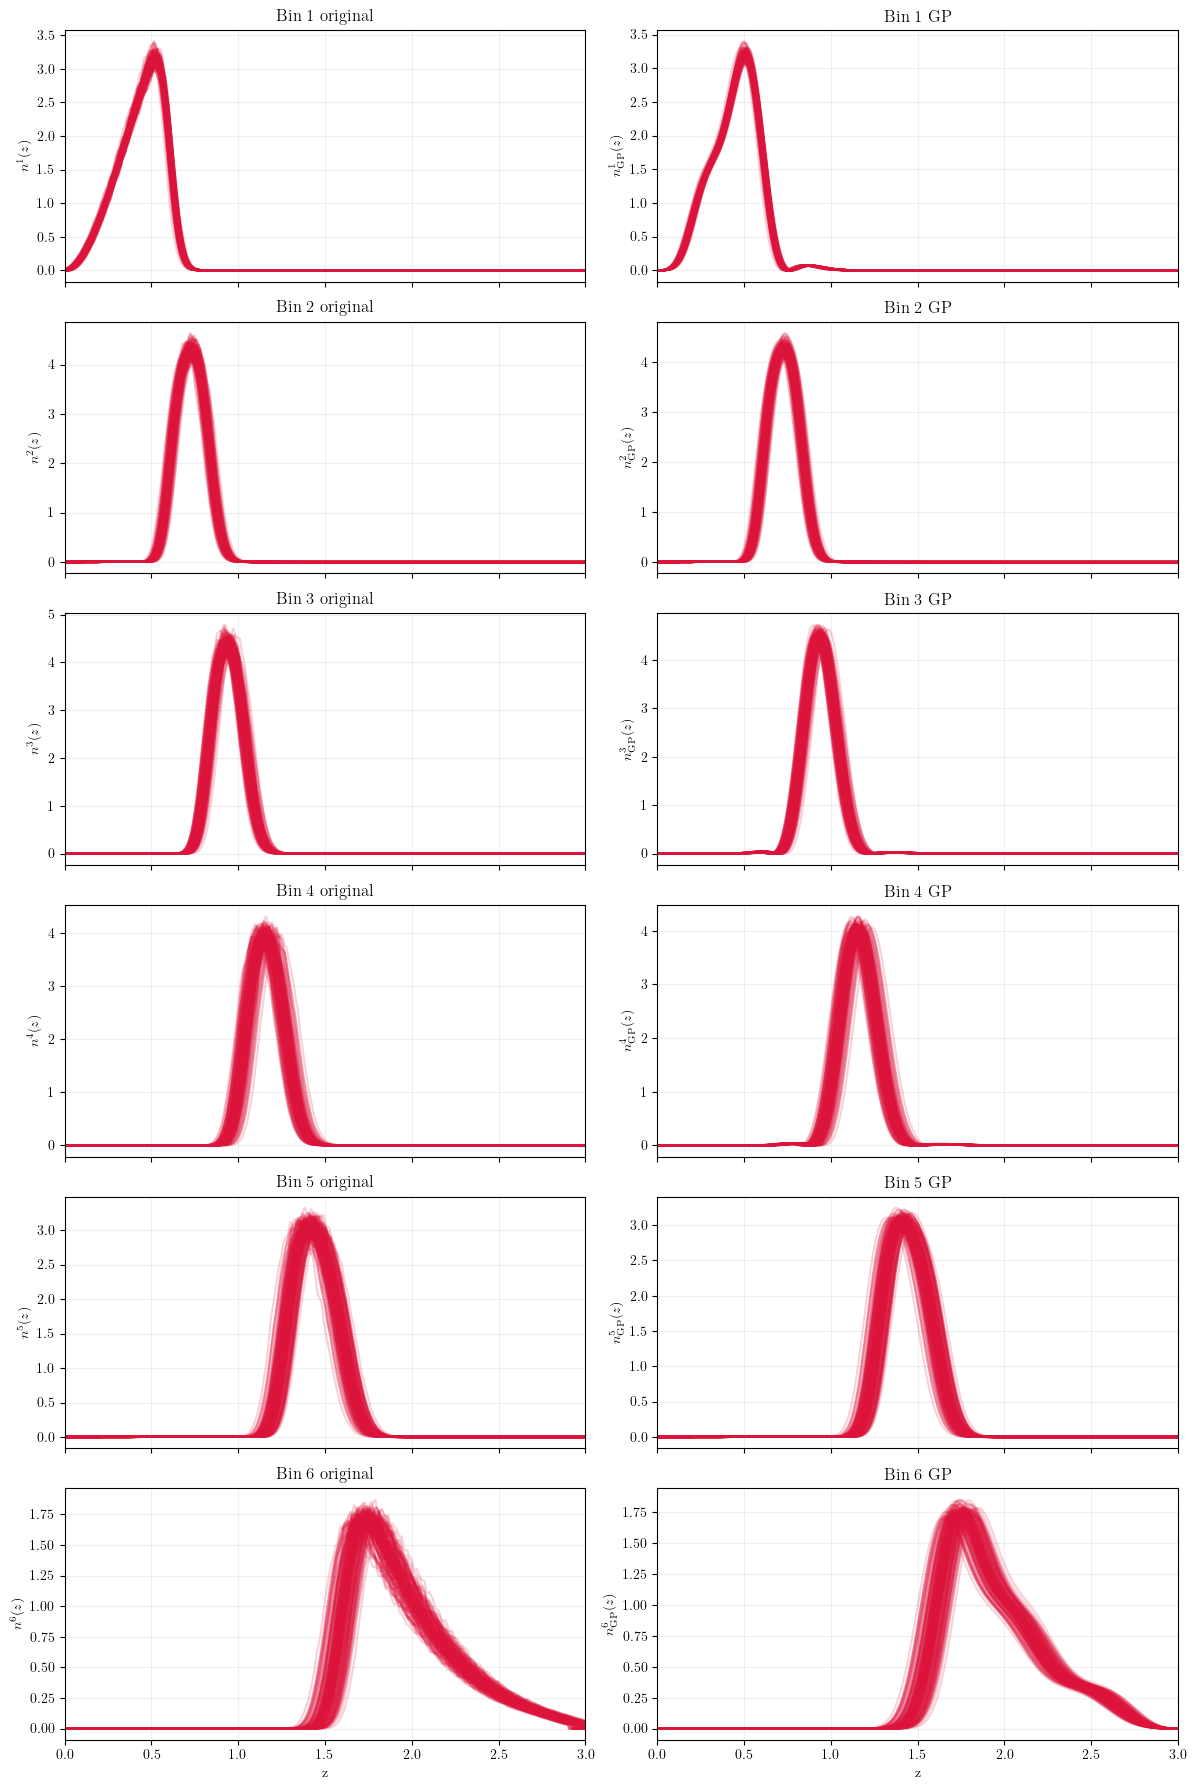

In [58]:
# Plotting original ensemble together with ensemble constructed from GPs 

fig, axes = plt.subplots(6, 2, figsize=(12, 18), sharex=True)

for b in range(6):
    z_grid = z_ens_list[b]
    nz_ens = nz_ensemble_list[b]
    nz_gp_ens = nz_gp_ens_all_bins[b]

    for k in range(len(nz_ens)):
        axes[b, 0].plot(z_grid, nz_ens[k], color="crimson", alpha=0.2)
        axes[b, 1].plot(z_grid, nz_gp_ens[k], color="crimson", alpha=0.2)

    axes[b, 0].set_ylabel(r"$n^{" + str(b+1) + r"}(z)$")
    axes[b, 1].set_ylabel(r"$n^{" + str(b+1) + r"}_{\rm GP}(z)$")

    axes[b, 0].set_title(f"Bin {b+1} original")
    axes[b, 1].set_title(f"Bin {b+1} GP")

    axes[b, 0].grid(alpha=0.2)
    axes[b, 1].grid(alpha=0.2)

axes[-1, 0].set_xlabel("z")
axes[-1, 1].set_xlabel("z")
axes[-1, 0].set_xlim(0,3)
axes[-1, 1].set_xlim(0,3)

plt.tight_layout()

(6, 200, 7)


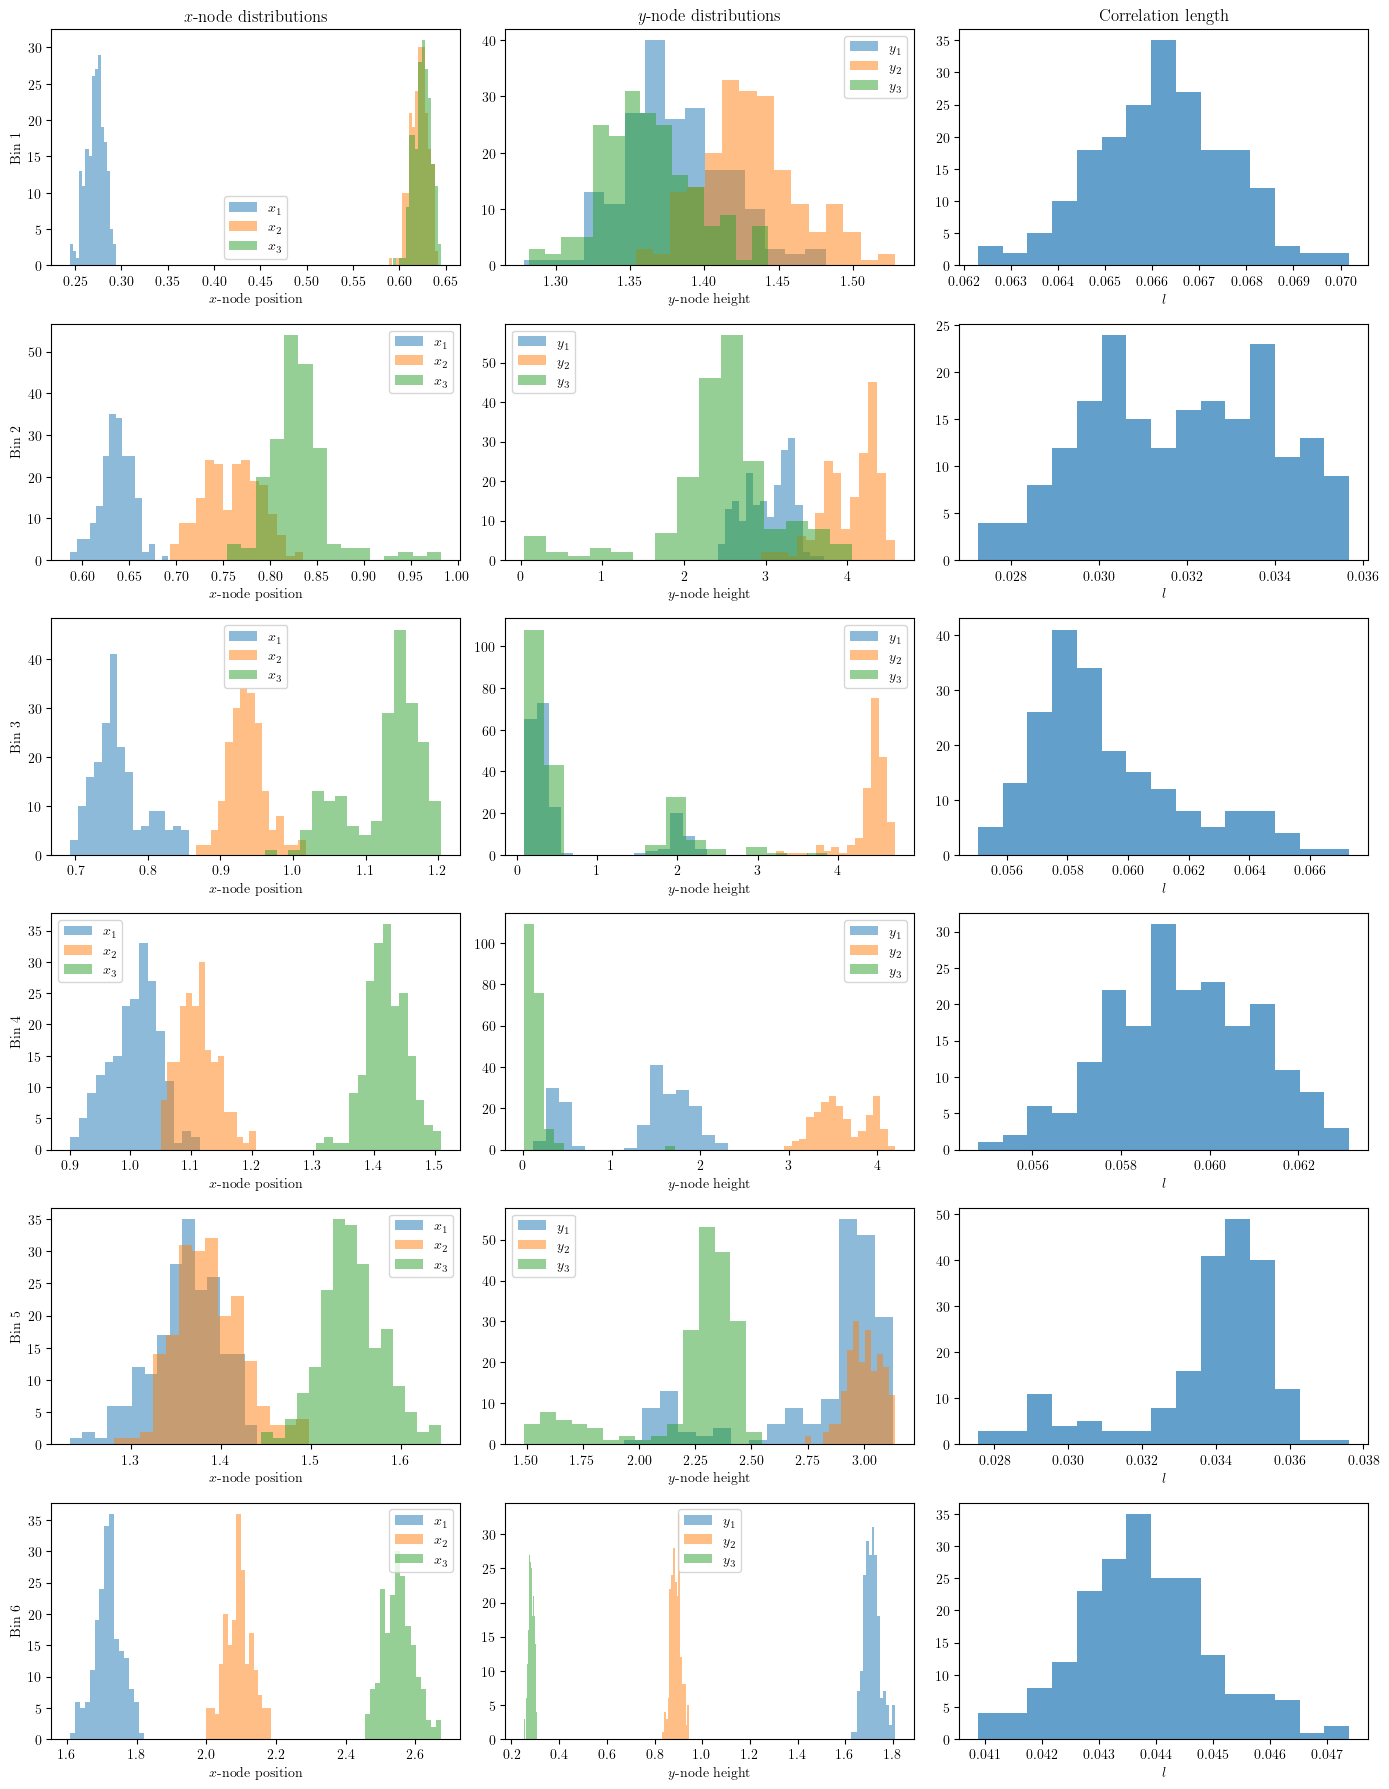

In [59]:
# Plotting the resulting distribution of GP params 

print(np.array(GP_params_all_bins).shape) # 6 bins, 50 realisations, 7 GP params (3 x-nodes, 3 y-nodes, 1 correlation length)
GP_params_array = np.array(GP_params_all_bins)

fig, axes = plt.subplots(6, 3, figsize=(14, 18))

for b in range(6):
    x_nodes = GP_params_array[b, :, :3]
    y_nodes = GP_params_array[b, :, 3:6]
    ell = GP_params_array[b, :, 6]

    for i in range(3):
        axes[b, 0].hist(x_nodes[:, i], bins=15, alpha=0.5, label=fr"$x_{i+1}$")
        axes[b, 1].hist(y_nodes[:, i], bins=15, alpha=0.5, label=fr"$y_{i+1}$")

    axes[b, 2].hist(ell, bins=15, alpha=0.7)

    axes[b, 0].set_ylabel(f"Bin {b+1}")
    axes[b, 0].legend()
    axes[b, 1].legend()

axes[0, 0].set_title("$x$-node distributions")
axes[0, 1].set_title("$y$-node distributions")
axes[0, 2].set_title("Correlation length")

for b in range(6):
    axes[b, 0].set_xlabel("$x$-node position")
    axes[b, 1].set_xlabel("$y$-node height")
    axes[b, 2].set_xlabel(r"$l$")

plt.tight_layout()

3.2 Training the normalising flow on the GP params 

In [60]:
flows = []
means = []
stds = []

for b in range(6):
    print(f"Training flow for bin {b+1}")
    flow_b, mean_b, std_b = norm_flow_per_bin(GP_params_all_bins[b], n_layers=5, hidden_features=32)
    flows.append(flow_b)
    means.append(mean_b)
    stds.append(std_b)

Training flow for bin 1


Training flow: 100%|███████████████████████████████████████████| 3000/3000 [00:22<00:00, 134.25it/s]


Training flow for bin 2


Training flow: 100%|███████████████████████████████████████████| 3000/3000 [00:19<00:00, 154.77it/s]


Training flow for bin 3


...

Training flow: 100%|███████████████████████████████████████████| 3000/3000 [00:20<00:00, 143.75it/s]


Training flow for bin 5


Training flow: 100%|███████████████████████████████████████████| 3000/3000 [00:19<00:00, 151.22it/s]


Training flow for bin 6


Training flow: 100%|███████████████████████████████████████████| 3000/3000 [00:19<00:00, 150.54it/s]


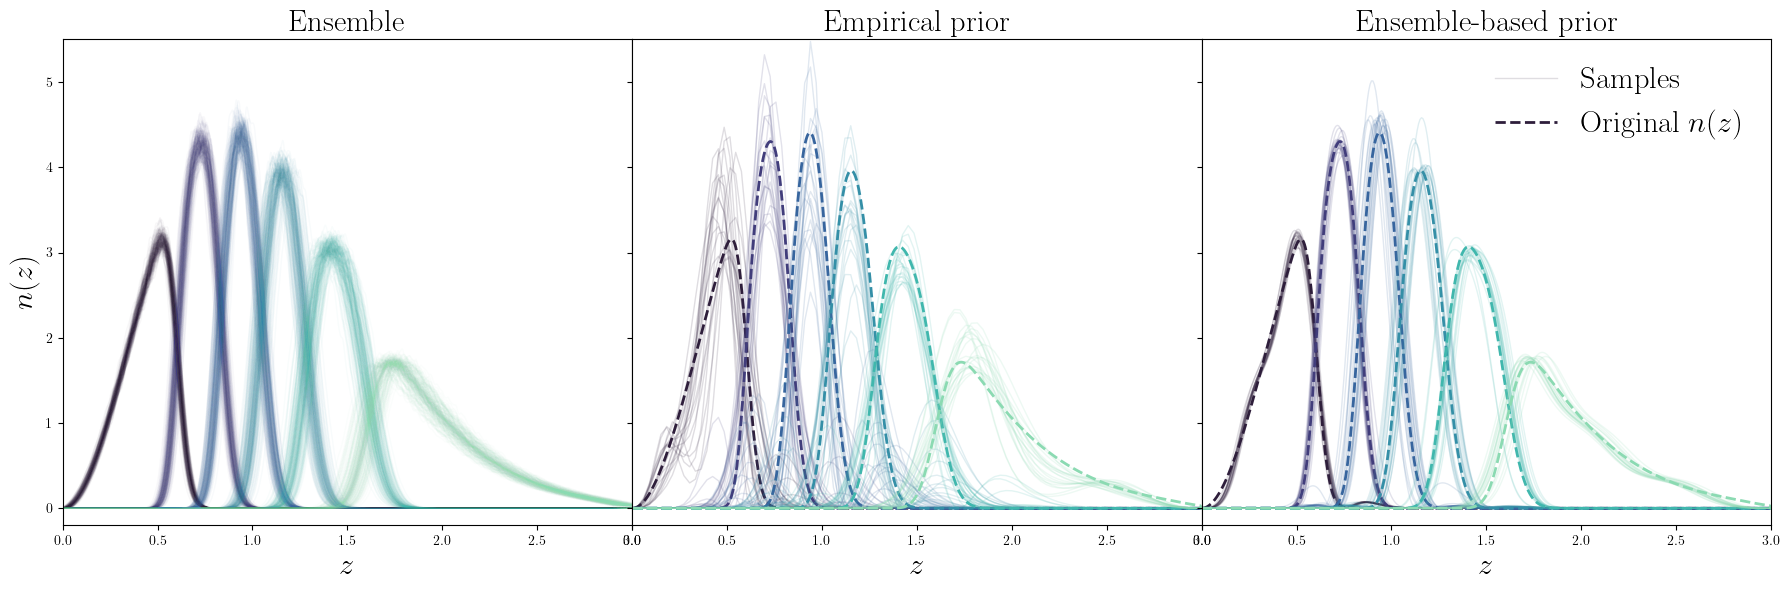

In [68]:
n_samples = 20

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True, gridspec_kw={"wspace": 0})
palette = sns.color_palette("mako", 6)
z_pred_res = z_pred.reshape(-1, 1)
x_nodes_all, y_nodes_all = compute_cdf_nodes(z_nz, dndz_she_norm, 3)
rng = np.random.default_rng()
delta = 0.05

ax = axes[0]

for b, nz_ens in enumerate(nz_ensemble_list):
    z_ens = z_ens_list[b]
    for nz in nz_ens:
        ax.plot(z_ens, nz, color=palette[b], alpha=0.03, lw=1)
ax.set_xlabel(r"$z$", fontsize=22)
ax.set_ylabel(r"$n(z)$", fontsize=22)
ax.set_xlim(0, 3)
ax.set_ylim(-0.2, 4.5)
ax.set_title("Ensemble", fontsize=22)

ax = axes[1]
for j, _ in enumerate(x_nodes_all):    
    for s in range(n_samples):
        x_sample = np.array(x_nodes_all[j]) + rng.uniform(-delta, delta, len(x_nodes_all[j]))
        y_sample = np.array(y_nodes_all[j]) + rng.uniform(-delta, delta, len(y_nodes_all[j]))
        order = np.argsort(x_sample)
        x_sample = x_sample[order]
        y_sample = y_sample[order]

        x_tmp = list(x_nodes_all)
        y_tmp = list(y_nodes_all)
        x_tmp[j] = x_sample
        y_tmp[j] = y_sample

        corr_len_sample = rng.uniform(0.05, 0.08)
        y_pred_sample = reconstruct_all_bins(z_pred, x_tmp, y_tmp, corr_len=corr_len_sample)
        y_pred_sample_norm = resample_dndz_gp(y_pred_sample, z_pred_res, zs)
        ax.plot(zs, y_pred_sample_norm[j], color=palette[j], alpha=0.15, lw=1)
    ax.plot(z_nz, dndz_she_norm[j + 1], '--', color=palette[j], alpha=1, lw=2)

ax.set_xlabel(r"$z$", fontsize=22)
ax.set_xlim(0, 3)
ax.set_ylim(-0.2, 4.5)
ax.set_title("Empirical prior", fontsize=22)


ax = axes[2]

for b in range(len(flows)):
    flow = flows[b]
    mean = means[b]
    std = stds[b]

    U_flow_norm = flow.sample(n_samples).detach().numpy()
    GP_flow = U_flow_norm * std + mean

    x_flow = GP_flow[:, :3]
    y_flow = GP_flow[:, 3:2*3]
    ell_flow = GP_flow[:, 2*3]

    for i in range(len(GP_flow)):
        if ell_flow[i] < 0 or np.any(y_flow[i] < 0):
            continue

        y_pred = reconstruct_per_bin(z_pred, x_flow[i], y_flow[i], z_bounds=(0.0, 3.0), corr_len=ell_flow[i],
            amp=0.04, alpha=0.0, kernel_class=RBF, nu=1.5, return_std=False)

        ax.plot(z_pred, y_pred, color=palette[b], alpha=0.15, lw=1, label='Samples' if i == 0 and b == 0 else None)
    ax.plot(z_nz, dndz_she_norm[b + 1], '--', color=palette[b], alpha=1, lw=2,
            label="Original $n(z)$" if b == 0 else None)

ax.set_xlabel(r"$z$", fontsize=22)
ax.set_xlim(0, 3)
ax.set_ylim(-0.2, 5.5)
ax.set_title("Ensemble-based prior", fontsize=22)
ax.legend(loc="upper right", fontsize=22, frameon=False)

plt.tight_layout()

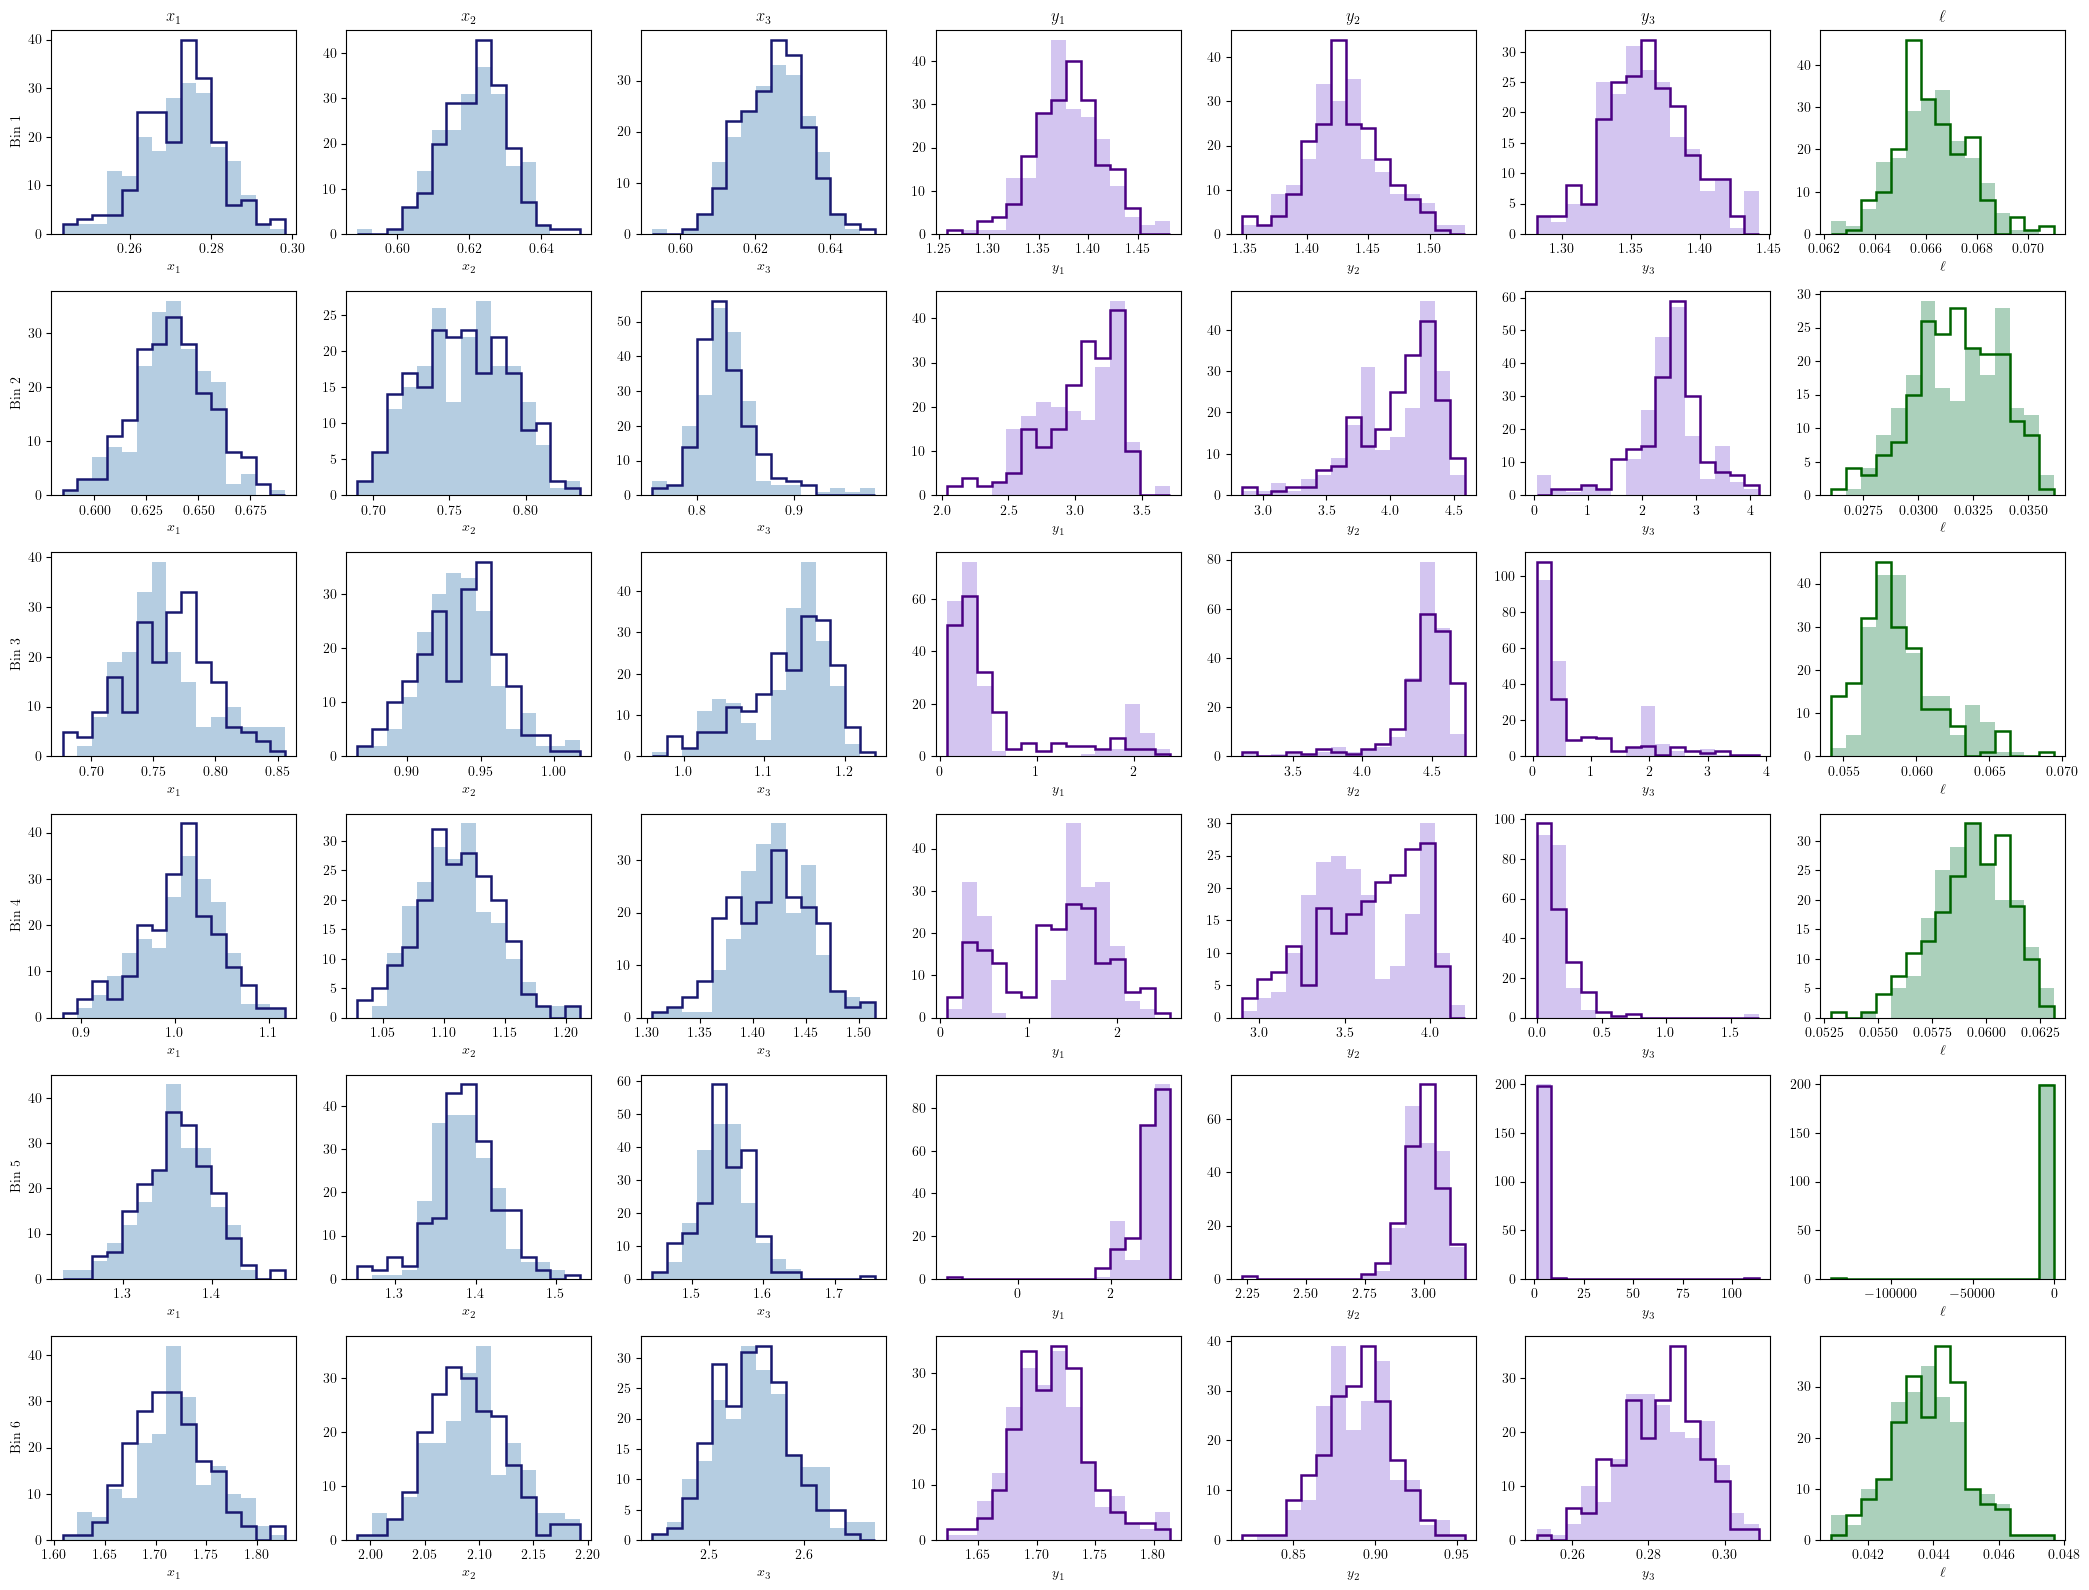

In [69]:
GP_params_array = np.array(GP_params_all_bins)

x_color = "steelblue"
x_dark = "midnightblue"
y_color = "mediumpurple"
y_dark = "indigo"
ell_color = "seagreen"
ell_dark = "darkgreen"

fig, axes = plt.subplots(6, 7, figsize=(21, 16))

for b in range(6):
    x_nodes = GP_params_array[b, :, :3]
    y_nodes = GP_params_array[b, :, 3:6]
    ell = GP_params_array[b, :, 6]

    flow_samples_norm = flows[b].sample(200).detach().numpy()
    flow_samples = flow_samples_norm * stds[b] + means[b]

    x_flow = flow_samples[:, :3]
    y_flow = flow_samples[:, 3:6]
    ell_flow = flow_samples[:, 6]



    for i in range(3):
        bins_x = np.histogram_bin_edges(np.concatenate([x_nodes[:, i], x_flow[:, i]]), bins=15)
        axes[b, i].hist(x_nodes[:, i], bins=bins_x, alpha=0.4, color=x_color)
        axes[b, i].hist(x_flow[:, i], bins=bins_x, histtype="step", linewidth=1.8, color=x_dark)
        axes[b, i].set_xlabel(fr"$x_{i+1}$")

    for i in range(3):
        bins_y = np.histogram_bin_edges(np.concatenate([y_nodes[:, i], y_flow[:, i]]), bins=15)
        axes[b, i+3].hist(y_nodes[:, i], bins=bins_y, alpha=0.4, color=y_color)
        axes[b, i+3].hist(y_flow[:, i], bins=bins_y, histtype="step", linewidth=1.8, color=y_dark)
        axes[b, i+3].set_xlabel(fr"$y_{i+1}$")

    bins_ell = np.histogram_bin_edges(np.concatenate([ell, ell_flow]), bins=15)
    axes[b, 6].hist(ell, bins=bins_ell, alpha=0.4, color=ell_color)
    axes[b, 6].hist(ell_flow, bins=bins_ell, histtype="step", linewidth=1.8, color=ell_dark)
    axes[b, 6].set_xlabel(r"$\ell$")

    axes[b, 0].set_ylabel(f"Bin {b+1}")

axes[0, 0].set_title("$x_1$")
axes[0, 1].set_title("$x_2$")
axes[0, 2].set_title("$x_3$")
axes[0, 3].set_title("$y_1$")
axes[0, 4].set_title("$y_2$")
axes[0, 5].set_title("$y_3$")
axes[0, 6].set_title("$\\ell$")

plt.tight_layout()
#plt.savefig('/home/jipdebuck/plots_flow/distributions_2.pdf', bbox_inches='tight')